# Домашняя работа 6.1. Перенос импульса по кольцу
## Зелёный уровень

$$
u_t+c u_x=0,\qquad c=1,\qquad x\in[0,1),
$$

$$
u_0(x)=1+\frac12\sin(2\pi x),\qquad
u(x,t)=u_0((x-t)\bmod1).
$$

После одного и пяти оборотов точный профиль совпадает с начальным.
Периодическая сетка содержит $N$ узлов: $x_j=j/N$, $j=0,\ldots,N-1$.
Точка $x=1$ не дублируется. Используются NumPy и Matplotlib.
[Условие задания](https://github.com/yartmihant/Students6Year2026#readme).

## 1. Разностные схемы

При $c>0$ схема upwind имеет вид

$$
u_j^{n+1}=u_j^n-C(u_j^n-u_{j-1}^n).
$$

Схема Лакса–Вендроффа:

$$
u_j^{n+1}=u_j^n-\frac C2(u_{j+1}^n-u_{j-1}^n)
+\frac{C^2}{2}(u_{j+1}^n-2u_j^n+u_{j-1}^n).
$$

Индексы берутся по модулю $N$. На всех шагах $C=0.8$, $\Delta t=0.8\Delta x$.
При $N=50$ один оборот занимает 62.5 шага. Поэтому в заданный момент
используется линейная интерполяция между двумя соседними слоями.
Шаг интегрирования не меняется. Для гладкого решения ошибка этой интерполяции
имеет порядок $O(\Delta t^2)$ и входит в приведённую ошибку.
При $N=100$ и $200$ моменты 1 и 5 точно совпадают с временными слоями.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.25})

C = 0.8
sizes = [50, 100, 200]
targets = [1.0, 5.0]


def initial(x):
    return 1 + 0.5 * np.sin(2 * np.pi * x)


def exact(x, t):
    return initial((x - t) % 1)


def step(u, method):
    left, right = np.roll(u, 1), np.roll(u, -1)
    if method == "Upwind":
        return u - C * (u - left)
    return u - C * (right - left) / 2 + C**2 * (right - 2*u + left) / 2


def sample(layers, t, dt):
    position = t / dt
    nearest = round(position)
    if abs(position - nearest) < 1e-10:
        return layers[nearest].copy()
    n = int(np.floor(position))
    weight = position - n
    return (1 - weight) * layers[n] + weight * layers[n + 1]


def solve(N, method):
    dx = 1 / N
    dt = C * dx
    x = np.arange(N) * dx
    count = int(np.ceil(max(targets) / dt))
    layers = np.empty((count + 1, N))
    layers[0] = initial(x)
    for n in range(count):
        layers[n + 1] = step(layers[n], method)
    return x, np.arange(count + 1) * dt, layers, dt


runs = {(N, method): solve(N, method) for N in sizes for method in ["Upwind", "LW"]}
errors = {}
print("N     Метод     t     E1             M              max |M(t)-M(0)|")
for (N, method), (x, time, layers, dt) in runs.items():
    mass = layers.mean(axis=1)
    for t in targets:
        u = sample(layers, t, dt)
        error = np.mean(np.abs(u - exact(x, t)))
        errors[N, method, t] = error
        print(f"{N:<6}{method:<10}{t:<6g}{error:.6e}   {u.mean():.12f}   "
              f"{np.max(np.abs(mass-mass[0])):.2e}")

N     Метод     t     E1             M              max |M(t)-M(0)|
50    Upwind    1     2.454094e-02   1.000000000000   3.33e-16
50    Upwind    5     1.040978e-01   1.000000000000   3.33e-16
50    LW        1     1.963223e-03   1.000000000000   6.66e-16
50    LW        5     9.493377e-03   1.000000000000   6.66e-16
100   Upwind    1     1.232215e-02   1.000000000000   4.44e-16
100   Upwind    5     5.702099e-02   1.000000000000   4.44e-16
100   LW        1     4.736781e-04   1.000000000000   4.44e-16
100   LW        5     2.368060e-03   1.000000000000   4.44e-16
200   Upwind    1     6.221657e-03   1.000000000000   2.22e-16
200   Upwind    5     2.991569e-02   1.000000000000   2.22e-16
200   LW        1     1.184318e-04   1.000000000000   3.33e-16
200   LW        5     5.921490e-04   1.000000000000   3.33e-16


## 2. Профили и ошибка

Вычисляются $E_1=\Delta x\sum_j|u_j-u(x_j,t)|$ и $M=\Delta x\sum_j u_j$.
Так как длина области равна единице, эти суммы совпадают со средними по узлам.
Точное количество примеси равно 1.

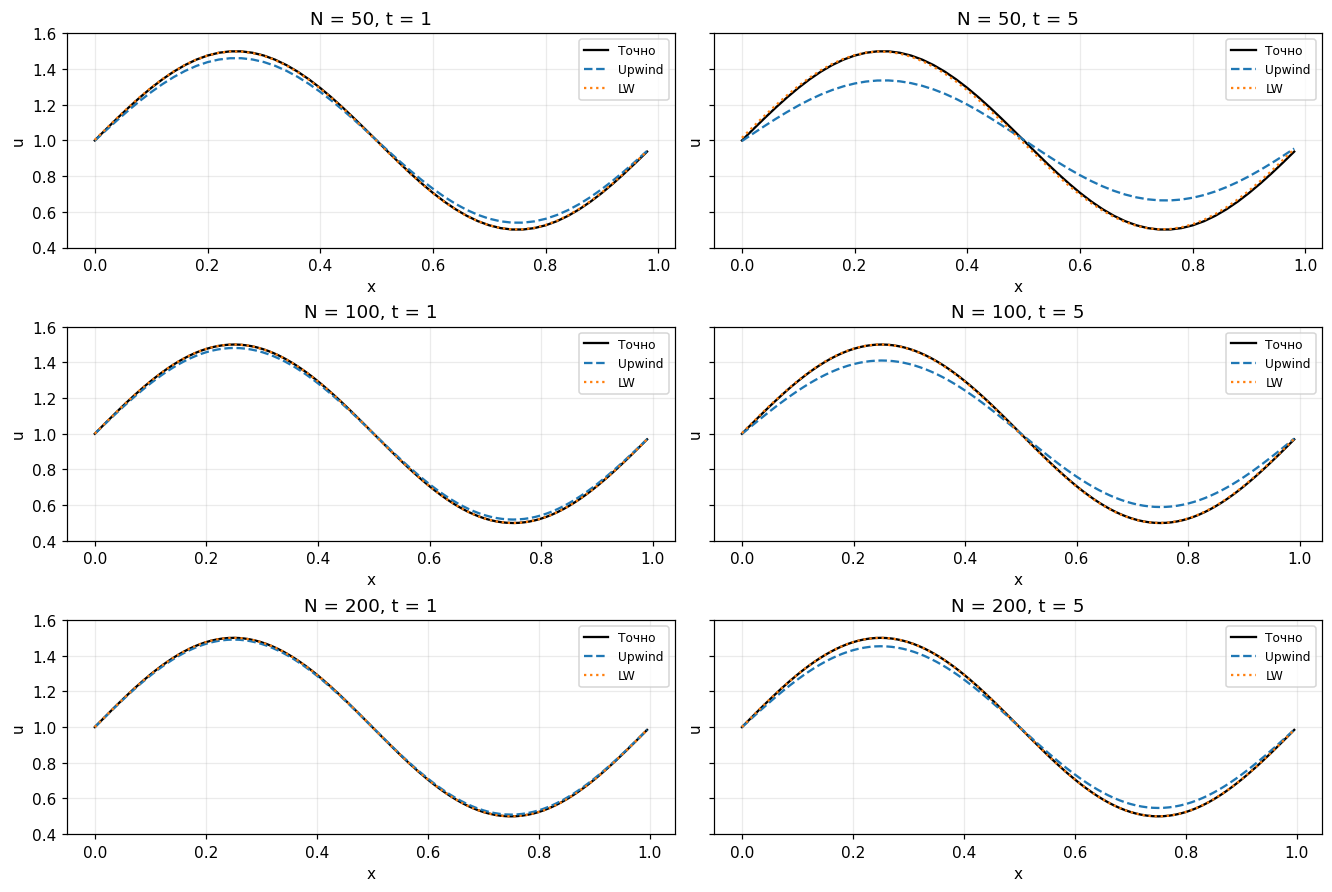

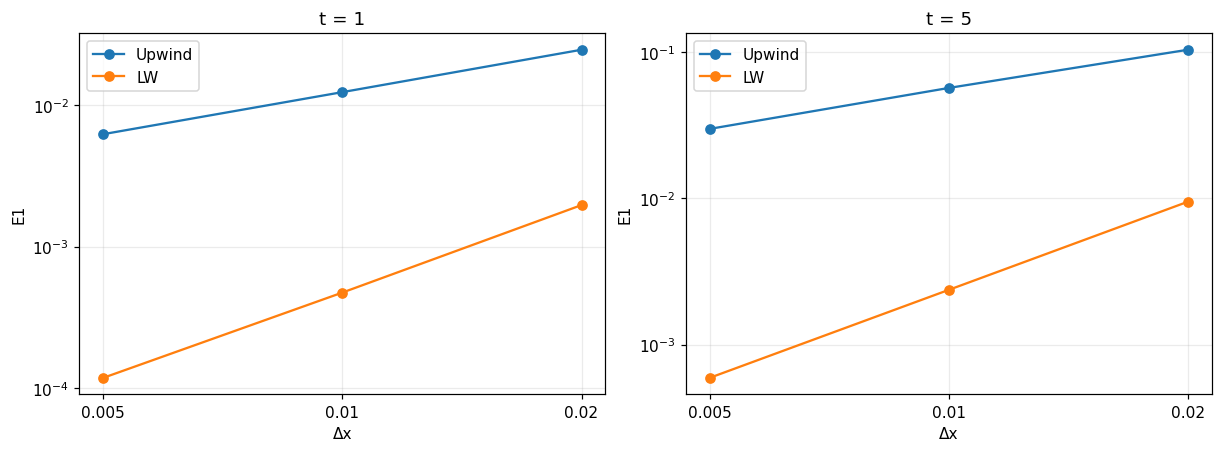

Порядки по E1: p = log2(E_N / E_2N)
t=1, Upwind: 0.994, 0.986
t=1, LW: 2.051, 2.000
t=5, Upwind: 0.868, 0.931
t=5, LW: 2.003, 2.000


In [2]:
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharey=True, layout="constrained")
for row, N in enumerate(sizes):
    for col, t in enumerate(targets):
        ax = axes[row, col]
        x = np.arange(N) / N
        ax.plot(x, exact(x, t), "k-", label="Точно")
        for method, style in [("Upwind", "--"), ("LW", ":")]:
            x, time, layers, dt = runs[N, method]
            ax.plot(x, sample(layers, t, dt), style, label=method)
        ax.set(title=f"N = {N}, t = {t:g}", xlabel="x", ylabel="u", ylim=(0.4, 1.6))
        ax.legend(fontsize=8)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, t in zip(axes, targets):
    for method in ["Upwind", "LW"]:
        values = np.array([errors[N, method, t] for N in sizes])
        ax.loglog(1/np.array(sizes), values, "o-", label=method)
    ax.set(title=f"t = {t:g}", xlabel="Δx", ylabel="E1")
    ax.set_xticks([1/N for N in sizes], [str(1/N) for N in sizes])
    ax.minorticks_off()
    ax.legend()
plt.show()
print("Порядки по E1: p = log2(E_N / E_2N)")
for t in targets:
    for method in ["Upwind", "LW"]:
        orders = [np.log2(errors[N, method, t]/errors[2*N, method, t]) for N in sizes[:-1]]
        print(f"t={t:g}, {method}: {orders[0]:.3f}, {orders[1]:.3f}")

## 3. Сохранение количества примеси

Суммы разностей в обеих схемах взаимно сокращаются на периодической сетке,
поэтому количество примеси сохраняется с точностью округления.
Интерполяция между слоями также сохраняет эту сумму.
Справа показан накопленный максимум абсолютного отклонения от начального количества;
его величина соответствует ошибкам округления.

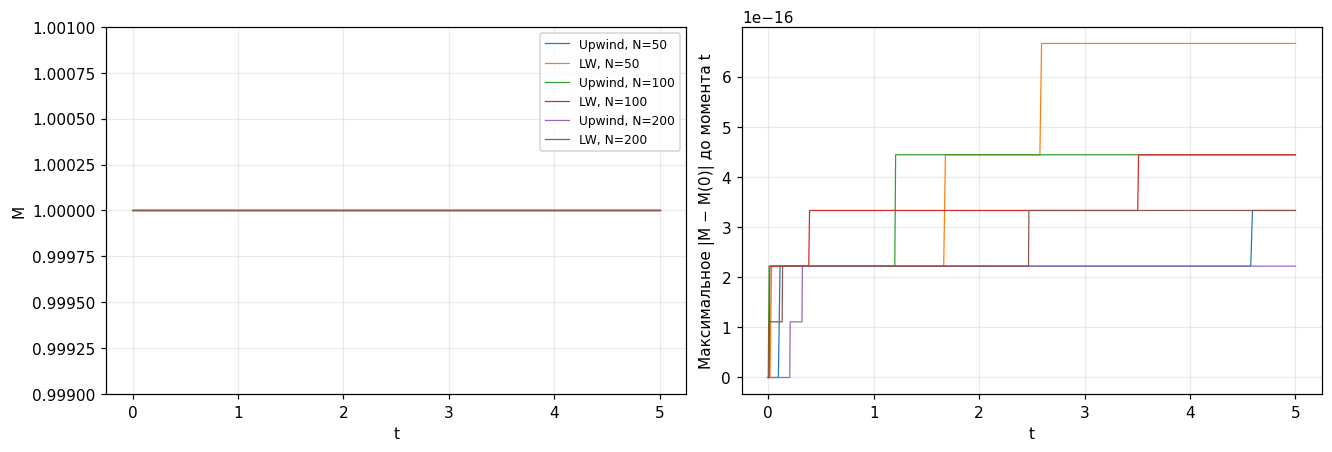

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for (N, method), (x, time, layers, dt) in runs.items():
    mask = time <= 5
    times = time[mask]
    mass = layers[mask].mean(axis=1)
    if times[-1] < 5 - 1e-12:
        times = np.append(times, 5)
        mass = np.append(mass, sample(layers, 5, dt).mean())
    label = f"{method}, N={N}"
    axes[0].plot(times, mass, label=label, linewidth=0.8)
    axes[1].plot(times, np.maximum.accumulate(np.abs(mass - layers[0].mean())), label=label, linewidth=0.8)
axes[0].set(xlabel="t", ylabel="M", ylim=(0.999, 1.001))
axes[1].set(xlabel="t", ylabel="Максимальное |M − M(0)| до момента t")
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useOffset=False)
axes[0].legend(fontsize=8)
plt.show()

## Выводы

Обе схемы сохраняют количество примеси, но численные профили отличаются от точного.
Upwind заметно уменьшает амплитуду синусоиды; после пяти оборотов это проявляется
сильнее. Схема Лакса–Вендроффа на гладком профиле точнее, хотя имеет фазовую ошибку.
При сгущении сетки ошибка upwind убывает примерно с первым порядком,
а ошибка Лакса–Вендроффа — со вторым.

Сохранение $M$ означает сохранение интеграла, но не распределения.
Например, постоянный профиль $u=1$ имеет такое же количество примеси,
как исходная синусоида. Поэтому сохранение массы нужно проверять вместе
с ошибкой профиля и сходимостью по сетке.